# Exploratory Data Analysis

Purchase occasions of *Everything & Then Some*. For each purchase we want to know whether the customer
buys again within 90 days, and how much they spend in that period.

The raw profile of every column (shapes, missing values, unique counts, test-only levels) is in
`docs/data_notes.md` and is not repeated here. This notebook only looks at the data: no file is changed.
Where a section needs the impossible values removed (section 7), it works on a copy.

| Section | Content |
|---|---|
| 1 | Data card: the role of every column |
| 2 | Targets |
| 3 | Placeholders and category hygiene |
| 4 | Invalid values: domain rules and cross-column consistency |
| 5 | Duplicates |
| 6 | Missing values: structural gaps, mechanism test, missingness flags |
| 7 | Distributions by class |

## Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

ROOT = Path.cwd().parent              # the notebook runs from notebooks/
sys.path.append(str(ROOT))

from main import load_config
from src.data import load_raw

cfg = load_config()
train = load_raw(cfg, "train_file")
test = load_raw(cfg, "test_file")

CLS = cfg["data"]["targets"]["classification"]
REG = cfg["data"]["targets"]["regression"]
ID = cfg["data"]["id_column"]
GROUP = cfg["data"]["group_column"]
DATE = cfg["data"]["date_column"]
numeric = cfg["features"]["numeric"]
categorical = cfg["features"]["categorical"]

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "figure.dpi": 110})
COLOR = "#3b6ea5"
train.shape, test.shape

((6534, 40), (986, 38))

In [2]:
CLS, REG

('repeat_purchase_90d', 'spend_next_90d')

In [3]:
from pprint import pprint

print("cfg =")
pprint(cfg, sort_dicts=False)
print("\nCLS =", repr(CLS))
print("REG =", repr(REG))
print("\ntrain =")
train

cfg =
{'seed': 42,
 'data': {'dir': 'data/raw',
          'train_file': 'train.csv',
          'test_file': 'test.csv',
          'clientes_file': 'clientes.csv',
          'sample_submission_file': 'sample_submission.csv',
          'id_column': 'ID',
          'group_column': 'customer_id',
          'date_column': 'purchase_date',
          'targets': {'classification': 'repeat_purchase_90d',
                      'regression': 'spend_next_90d'},
          'clientes_columns': []},
 'cleaning': {'float_columns': ['N_ Detalhes',
                                'invoice_count_current_purchase',
                                'customer_tenure_days',
                                'prior_purchase_count',
                                'purchase_count_30d',
                                'purchase_count_90d',
                                'purchase_count_180d',
                                'purchase_count_365d']},
 'features': {'numeric': ['Total a Pagar',
                       

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.0,0.00,57.15,153.099911,4.0,1.0,...,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.0,0.00,34.25,472.943134,32.0,1.0,...,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.0,0.00,3.60,6.097485,1.0,1.0,...,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.0,0.00,0.00,408.167275,9.0,1.0,...,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.0,0.00,174.95,485.401864,33.0,1.0,...,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6529,3023.34,3761.38,2458.00,565.34,0.0,0.00,1303.38,1099.190000,49.0,1.0,...,151492,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 72,Final Excel Warehouse 1,Ctrl Z Series 3,2016-01-24,10007670,-1.579719
6530,1362.26,1723.10,1107.53,254.73,0.0,34.25,581.32,197.514000,16.0,1.0,...,975873,Maybe Tomorrow Payment 12,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 1,2021-04-13,10007671,-0.576883
6531,4396.55,3574.43,3574.43,822.12,0.0,0.00,0.00,2075.838024,78.0,1.0,...,755628,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 72,Final Excel Warehouse 1,Ctrl Z Series 2,2022-03-19,10007672,0.528377
6532,452.07,483.60,367.54,84.53,0.0,0.00,116.06,265.159468,7.0,1.0,...,703834,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 40,Final Excel Warehouse 1,Ctrl Z Series 1,2019-03-23,10007673,1.012809


`cfg` is the full content of `config.yaml` as a nested dictionary. `CLS` and `REG` are
strings which we took from `cfg["data"]["targets"]`, with the names of the two target columns. `train` is the
raw `train.csv` as a DataFrame, and `train[CLS]` / `train[REG]` select its target columns.


## 1. Data card

Every column gets one role before anything else. A column that is not listed under `features` in
`config.yaml` never reaches the model, without any error, so this check makes sure nothing is left out by accident.

| Role | Columns | Notes |
|---|---|---|
| **Targets** | `repeat_purchase_90d`, `spend_next_90d` | train only. Never features (hard rule) |
| **Identifier** | `ID` | row key, unique in both files. The Kaggle file is matched on it |
| **Grouping key** | `customer_id` | customers repeat across rows, so CV is grouped on it. Join key to `clientes.csv`. Not a feature |
| **Date** | `purchase_date` | not a feature as raw text. Test is strictly later than train (customers-and-time section, to come) |
| **Numeric features** | 8 monetary, 2 purchase details, 10 history, 8 rolling, `random_noise` | `random_noise` is kept as a sanity check for feature selection |
| **Categorical features** | `payment_type`, `salesperson`, `commercial_zone`, `transport_method`, `warehouse`, `document_series` | |
| **Customer table** | the `clientes.csv` columns | not chosen yet (`clientes.csv` section, to come) |

In [4]:
roles = {
    "target": [CLS, REG],
    "identifier": [ID],
    "grouping key": [GROUP],
    "date": [DATE],
    "numeric feature": numeric,
    "categorical feature": categorical,
}
role_of = {col: role for role, cols in roles.items() for col in cols}

pd.Series({
    "columns in train.csv": train.shape[1],
    "columns with a role": len(role_of),
    "train columns without a role": [c for c in train.columns if c not in role_of],
    "test columns without a role": [c for c in test.columns if c not in role_of],
    "roles naming a column that doesn't exist": [c for c in role_of if c not in train.columns],
}).to_frame("value")

,value
columns in train.csv,40
columns with a role,40
train columns without a role,[]
test columns without a role,[]
roles naming a column that doesn't exist,[]


`role_of` maps each column name to its role. All 40 train columns have exactly one role, and test has the same
columns minus the two targets.

## 2. Targets

Our two targets (ONLY in `train.csv` !!):

- `repeat_purchase_90d`: 1 if the customer buys again within 90 days (classification)
- `spend_next_90d`: how much they spend in those 90 days (numerical/regression)

### 2.1 Classification target

In [5]:
counts = train[CLS].value_counts()
pd.DataFrame({"rows": counts, "share": (counts / len(train)).round(3)})

,rows,share
repeat_purchase_90d,,
1,3654,0.559
0,2880,0.441


Share is the proportion of each class in the dataset.

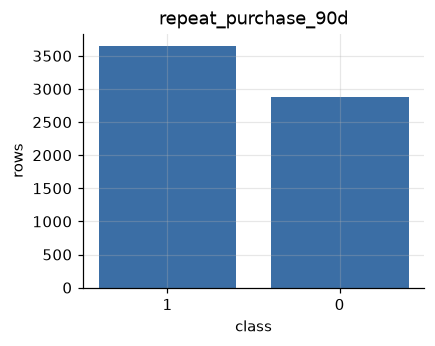

In [6]:
fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(counts.index.astype(str), counts.values, color=COLOR)
ax.set(title="repeat_purchase_90d", xlabel="class", ylabel="rows")
plt.show()

The classes are rather balanced: about 56% of purchases are followed by another one within 90 days

### 2.2 Positive rate over time

Is the share of returning customers stable across the years?

In [7]:
year = pd.to_datetime(train["purchase_date"]).dt.year
by_year = train.groupby(year)[CLS].agg(rows="size", positive_rate="mean").round(3)
by_year.index = by_year.index.astype(int)
by_year.T

purchase_date,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
rows,335.000,420.000,670.000,716.000,646.000,670.000,782.000,628.000,767.000,757.000,78.000
positive_rate,0.534,0.514,0.633,0.538,0.522,0.594,0.549,0.481,0.581,0.602,0.628


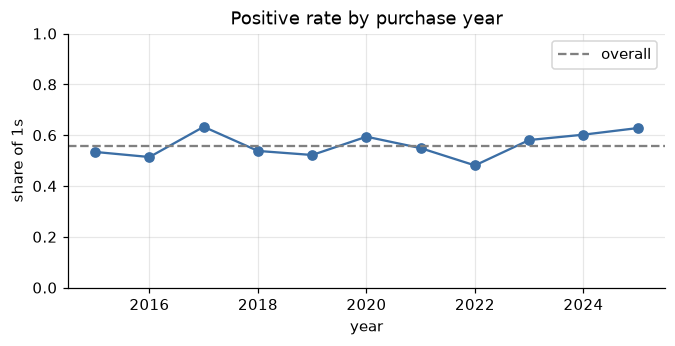

In [8]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(by_year.index, by_year["positive_rate"], marker="o", color=COLOR)
ax.axhline(train[CLS].mean(), color="grey", linestyle="--", label="overall")
ax.set(title="Positive rate by purchase year", xlabel="year", ylabel="share of 1s", ylim=(0, 1))
ax.legend()
plt.show()

The rate moves between 0.48 and 0.63 with no clear trend. 2025 has only 78 rows, so its rate is less
reliable. The 65 rows without a date are not in the table.

### 2.3 Where the regression target exists

In [9]:
pd.crosstab(train[CLS], train[REG].notna().map({True: "spend filled", False: "spend missing"}), margins=True)

spend_next_90d,spend filled,spend missing,All
repeat_purchase_90d,,,
0,0,2880,2880
1,3425,229,3654
All,3425,3109,6534


`pd.crosstab` counts how many rows fall into each combination of two columns.


Spend is only filled for returning customers, as expected. 229 returning customers have no spend value,
which leaves 3,425 rows with a regression target.

### 2.4 Distribution of `spend_next_90d`

Only the rows where spend is filled.

In [10]:
spend = train[REG].dropna()
summary = spend.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
summary["skewness"] = spend.skew()
summary["kurtosis"] = spend.kurt()
summary.round(2).to_frame().T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skewness,kurtosis
spend_next_90d,3425.0,1921.53,2571.05,1.27,12.86,64.34,318.48,985.74,2464.56,6800.26,12115.81,25654.33,3.04,14.29


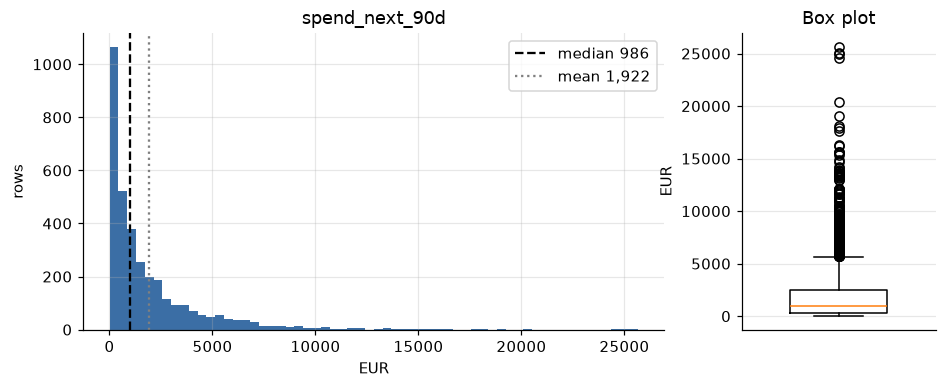

In [11]:
fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(10, 3.5), gridspec_kw={"width_ratios": [3, 1]})
ax_hist.hist(spend, bins=60, color=COLOR)
ax_hist.axvline(spend.median(), color="black", linestyle="--", label=f"median {spend.median():,.0f}")
ax_hist.axvline(spend.mean(), color="grey", linestyle=":", label=f"mean {spend.mean():,.0f}")
ax_hist.set(title="spend_next_90d", xlabel="EUR", ylabel="rows")
ax_hist.legend()
ax_box.boxplot(spend, widths=0.5)
ax_box.set(title="Box plot", ylabel="EUR", xticks=[])
plt.show()

In [12]:
bins = [0, 1000, 2000, 3000, 5000, 10000, spend.max()]
binned = pd.cut(spend, bins).value_counts().sort_index()
pd.DataFrame({"rows": binned, "share": (binned / len(spend)).round(3),
              "cumulative share": (binned.cumsum() / len(spend)).round(3)})

,rows,share,cumulative share
spend_next_90d,,,
"(0.0, 1000.0]",1727,0.504,0.504
"(1000.0, 2000.0]",641,0.187,0.691
"(2000.0, 3000.0]",360,0.105,0.796
"(3000.0, 5000.0]",343,0.100,0.897
"(5000.0, 10000.0]",289,0.084,0.981
"(10000.0, 25654.33]",65,0.019,1.000


Half of the returning customers spend under about 1,000 EUR in the next 90 days, but a few spend up to
25,654 EUR. The mean is about twice the median, and many points sit above the upper whisker of the
box plot: the distribution has a long right tail.

### 2.5 The extremes

Are the largest and smallest values plausible, or do they look like errors (a repeated value, a cap,
zeros)?

In [13]:
q1, q3 = spend.quantile([0.25, 0.75])
pd.Series({
    "largest 5": spend.nlargest(5).round(2).tolist(),
    "smallest 5": spend.nsmallest(5).round(2).tolist(),
    "above Q3 + 3 IQR": int((spend > q3 + 3 * (q3 - q1)).sum()),
    "below 10 EUR": int((spend < 10).sum()),
    "zero or negative": int((spend <= 0).sum()),
}).to_frame("value")

,value
largest 5,"[25654.33, 25035.85, 24997.81, 24564.56, 20358..."
smallest 5,"[1.27, 1.33, 1.69, 1.98, 2.32]"
above Q3 + 3 IQR,88
below 10 EUR,25
zero or negative,0


The largest values are all different, so they do not look like a placeholder or a cap. There are no
zeros or negatives. The very high and very low amounts look like real customers, not data errors.

## 3. Placeholders and category hygiene

`.isna()` only finds values that are already empty. A missing value can also hide as text in a numeric
column (`"-"`, `"?"`), as a second spelling of the same category, or as an impossible number.

### 3.1 Column types

In [14]:
train.select_dtypes(exclude="number").columns.tolist()

['payment_type',
 'salesperson',
 'commercial_zone',
 'transport_method',
 'warehouse',
 'document_series',
 'purchase_date']

Only the six categoricals and the date are read as text. Every numeric column is read as numbers, so no text
token is hiding in one of them.

### 3.2 Category spellings

In [15]:
rows = []
for col in categorical:
    values = pd.concat([train[col], test[col]]).dropna()
    rows.append({
        "column": col,
        "levels": values.nunique(),
        "example": values.iloc[0],
        "every value is '<label> <number>'": bool(values.str.fullmatch(r"[A-Za-z ]+ \d+").all()),
        "levels merged by strip + lowercase": values.nunique() - values.str.strip().str.lower().nunique(),
    })
pd.DataFrame(rows)

,column,levels,example,every value is '<label> <number>',levels merged by strip + lowercase
0,payment_type,12,Maybe Tomorrow Payment 10,True,0
1,salesperson,9,VLOOKUP Master 9,True,0
2,commercial_zone,7,Decorative Dashboard Zone 4,True,0
3,transport_method,82,Maybe Tomorrow Delivery 61,True,0
4,warehouse,3,Final Excel Warehouse 1,True,0
5,document_series,3,Ctrl Z Series 2,True,0


In [16]:
dates = pd.to_datetime(train[DATE], errors="coerce")
pd.Series({
    "train dates that fail to parse": int((dates.isna() & train[DATE].notna()).sum()),
    "train dates missing": int(train[DATE].isna().sum()),
    "test dates missing": int(test[DATE].isna().sum()),
}).to_frame("rows")

,rows
train dates that fail to parse,0
train dates missing,65
test dates missing,0


Every category value follows the same `<label> <number>` pattern, and stripping spaces or lowercasing merges
no levels: there are no spelling variants and no `"?"`/`"n/a"` stand-ins. Every date parses. The 65 missing
dates are the 65 empty rows (section 6).

### 3.3 Impossible numbers used as placeholders

A placeholder in a numeric column shows up as a value far above everything else. The ratio between the
maximum and the 99th percentile finds it.

In [17]:
spread = pd.DataFrame({"99th percentile": train[numeric].quantile(0.99), "max": train[numeric].max()})
spread["max / p99"] = spread["max"] / spread["99th percentile"].replace(0, np.nan)
spread.sort_values("max / p99", ascending=False).head(6).round(1)

,99th percentile,max,max / p99
prior_mean_purchase_value,5230.1,1.000000e+09,191201.2
spend_365d,40876.8,1.000000e+09,24463.8
Total Desc_ Global,7.8,2.185000e+02,27.8
prior_max_purchase_value,14433.4,2.675262e+05,18.5
Total Portes,11.8,1.811000e+02,15.3
prior_mean_gap_days,514.1,3.199000e+03,6.2


In [18]:
PLACEHOLDER = 1e9
placeholders = pd.DataFrame({"train": (train[numeric] == PLACEHOLDER).sum(), "test": (test[numeric] == PLACEHOLDER).sum()})
placeholders[placeholders.sum(axis=1) > 0]

,train,test
prior_mean_purchase_value,16,2
spend_365d,15,2


Two columns stand out by five orders of magnitude: `prior_mean_purchase_value` and `spend_365d` reach exactly
**1,000,000,000**. No customer spends a billion euros per purchase, so it is a placeholder for "unknown": 16 and
15 rows in train, and 2 and 2 in test. These become NaN. Test has them too, so the rule belongs in `cleaning.py`,
which runs on every file.

The next columns (`Total Desc_ Global`, `prior_max_purchase_value`, `Total Portes`) are 15-28 times their 99th
percentile: large, but not one repeated value. `prior_max_purchase_value` turns out to be wrong for another reason (4.2).

## 4. Invalid values

A value can be present and still impossible. Domain rules catch these: first rules on one column
(4.1), then rules that compare columns of the same row (4.2).

### 4.1 One column at a time: negatives

Counts, amounts and day differences can't be negative. `random_noise` is the only numeric column allowed below zero.

In [19]:
NON_NEGATIVE = [c for c in numeric if c != "random_noise"]
negatives = pd.DataFrame({"train": (train[NON_NEGATIVE] < 0).sum(), "test": (test[NON_NEGATIVE] < 0).sum()})
negatives = negatives[negatives.sum(axis=1) > 0]
negatives["distinct negative values (train)"] = [sorted(train.loc[train[c] < 0, c].round(2).unique())[:5] for c in negatives.index]
negatives

,train,test,distinct negative values (train)
days_since_previous_purchase,16,2,[-4.0]
prior_mean_purchase_value,16,2,"[-2478.66, -885.1, -883.51, -779.03, -757.48]"
prior_mean_gap_days,16,2,[-4.0]
spend_365d,15,2,"[-159115.18, -14740.29, -12638.05, -6795.47, -..."


In [20]:
per_purchase = train["prior_total_spend"] / train["prior_purchase_count"]
mean_value = train["prior_mean_purchase_value"]
negative_mean = mean_value < 0
valid_mean = mean_value.between(0, PLACEHOLDER, inclusive="left")
pd.Series({
    "valid rows where the mean == prior_total_spend / prior_purchase_count": f"{np.isclose(mean_value[valid_mean], per_purchase[valid_mean], rtol=1e-3).mean():.1%}",
    "negative means": int(negative_mean.sum()),
    "negative means where -value == prior_total_spend / prior_purchase_count": int(np.isclose(-mean_value[negative_mean], per_purchase[negative_mean], rtol=1e-3).sum()),
}).to_frame("value")

,value
valid rows where the mean == prior_total_spend / prior_purchase_count,99.2%
negative means,16
negative means where -value == prior_total_spend / prior_purchase_count,16


Four columns have negatives, in 15-16 train rows and 2 test rows each:

- `days_since_previous_purchase` and `prior_mean_gap_days`: always exactly **-4**. A code, not a measurement.
- `prior_mean_purchase_value`: in 99.2% of valid rows it equals `prior_total_spend / prior_purchase_count`, and all
  16 negatives are that value with the sign flipped.
- `spend_365d`: different amounts, also likely sign-flipped (e.g. -753.51 where the customer's total spend is 753.51).

**Decision:** set them to NaN, so they are imputed like any other gap (class 01: "impossible but not missing is
still missing"). Reversing the sign would also work for the means, but it assumes we know the cause.

Note for the correlation/VIF section: `prior_mean_purchase_value` is just `prior_total_spend / prior_purchase_count`,
so it repeats information the model already has.

### 4.2 Columns that disagree with each other

Each value can be valid on its own while the row is impossible: a 30-day count above the 90-day count, a
largest purchase above the customer's total spend. The placeholders and negatives from 3.3 and 4.1 are blanked
first, so these checks only find new problems.

In [21]:
def blank_placeholders_and_negatives(df: pd.DataFrame) -> pd.DataFrame:
    # A copy where the 1e9 placeholder and negative values are NaN.
    out = df.copy()
    values = out[NON_NEGATIVE]
    out[NON_NEGATIVE] = values.mask((values < 0) | (values == PLACEHOLDER))
    return out


def consistency_violations(df: pd.DataFrame, tol: float = 0.01) -> dict:
    # One boolean Series per rule: True where the row breaks it. Comparisons with NaN are never violations.
    count = df["prior_purchase_count"]
    return {
        "Total Liquido = Bruto - Desc Linha - Desc Global":
            (df["Total Bruto"] - df["Total Desc_ Linha"] - df["Total Desc_ Global"] - df["Total Liquido"]).abs() > tol,
        "Total a Pagar = Liquido + Imp":
            (df["Total a Pagar"] - df["Total Liquido"] - df["Total Imp_"]).abs() > tol,
        "purchase_count 30d <= 90d <= 180d <= 365d":
            (df["purchase_count_30d"] > df["purchase_count_90d"]) | (df["purchase_count_90d"] > df["purchase_count_180d"])
            | (df["purchase_count_180d"] > df["purchase_count_365d"]),
        "spend 30d <= 90d <= 180d <= 365d":
            (df["spend_30d"] > df["spend_90d"] + tol) | (df["spend_90d"] > df["spend_180d"] + tol)
            | (df["spend_180d"] > df["spend_365d"] + tol),
        "purchase_count_365d <= prior_purchase_count": df["purchase_count_365d"] > count,
        "spend_365d <= prior_total_spend": df["spend_365d"] > df["prior_total_spend"] + tol,
        "prior_max <= prior_total_spend": df["prior_max_purchase_value"] > df["prior_total_spend"] + tol,
        "prior_min <= prior_max": df["prior_min_purchase_value"] > df["prior_max_purchase_value"] + tol,
        "prior_mean = prior_total_spend / prior_purchase_count":
            (count > 0) & ~np.isclose(df["prior_mean_purchase_value"], df["prior_total_spend"] / count, rtol=1e-3)
            & df["prior_mean_purchase_value"].notna(),
        "days_since_previous <= customer_tenure": df["days_since_previous_purchase"] > df["customer_tenure_days"],
        "no prior purchases <=> tenure 0": count.eq(0) != df["customer_tenure_days"].eq(0),
    }


pd.DataFrame({
    name: {rule: int(v.sum()) for rule, v in consistency_violations(blank_placeholders_and_negatives(df)).items()}
    for name, df in [("train", train), ("test", test)]
})

,train,test
Total Liquido = Bruto - Desc Linha - Desc Global,0,0
Total a Pagar = Liquido + Imp,0,0
purchase_count 30d <= 90d <= 180d <= 365d,0,0
spend 30d <= 90d <= 180d <= 365d,0,0
purchase_count_365d <= prior_purchase_count,0,0
spend_365d <= prior_total_spend,39,7
prior_max <= prior_total_spend,45,6
prior_min <= prior_max,0,0
prior_mean = prior_total_spend / prior_purchase_count,46,7
days_since_previous <= customer_tenure,0,0


In [22]:
view = blank_placeholders_and_negatives(train)
should_be = {
    "prior_mean_purchase_value": view["prior_total_spend"] / view["prior_purchase_count"],  # the mean is total / count
    "prior_max_purchase_value": view["prior_total_spend"],                                 # an upper bound
    "spend_365d": view["prior_total_spend"],                                               # an upper bound
}
rules = consistency_violations(view)
broken = {
    "prior_mean_purchase_value": rules["prior_mean = prior_total_spend / prior_purchase_count"],
    "prior_max_purchase_value": rules["prior_max <= prior_total_spend"],
    "spend_365d": rules["spend_365d <= prior_total_spend"],
}
pd.DataFrame({
    col: (view.loc[broken[col], col] / should_be[col][broken[col]]).describe()[["count", "min", "50%", "max"]]
    for col in broken
}).T.round(1).rename(columns={"50%": "median"})

,count,min,median,max
prior_mean_purchase_value,46.0,8.5,16.1,24.8
prior_max_purchase_value,45.0,1.1,4.3,22.3
spend_365d,39.0,1.5,10.8,23.2


**Rules that hold in every row, in both files:**

- `Total Liquido = Bruto - Desc Linha - Desc Global` and `Total a Pagar = Liquido + Imp`. These are not errors, but
  they make these columns exact linear combinations of each other (for VIF).
- The rolling windows are nested (30d <= 90d <= 180d <= 365d), and the 365-day count never exceeds the prior
  purchase count. So the windows count *previous* purchases only, as a feature known at purchase time should
  (checked again in the leakage section).
- First purchases (`prior_purchase_count == 0`) are exactly the rows with tenure 0.

**Three rules break, in about 0.7% of rows each:**

| Column | Rule broken | Train | Test |
|---|---|---:|---:|
| `prior_mean_purchase_value` | not equal to total / count: 8 to 25 times too large | 46 | 7 |
| `prior_max_purchase_value` | the largest purchase is larger than all purchases together | 45 | 6 |
| `spend_365d` | last year's spend is larger than all-time spend | 39 | 7 |

The values look plausible on their own, and only a rule that compares columns catches them. The table above shows
how far each value is from its correct value (the mean) or from its upper bound (max, spend_365d).
**Decision:** NaN, as in 4.1.

### 4.3 All the rules together

The rules above, as one function: every impossible value becomes NaN. It looks at one row at a time and keeps
every row, so it can run unchanged on train, test and client input. This is what goes into `src/cleaning.py`.

In [23]:
def blank_invalid_values(df: pd.DataFrame) -> pd.DataFrame:
    # Placeholders, negatives and the three inflated columns become NaN. Same rows, same order.
    out = blank_placeholders_and_negatives(df)
    rules = consistency_violations(out)
    out.loc[rules["prior_mean = prior_total_spend / prior_purchase_count"], "prior_mean_purchase_value"] = np.nan
    out.loc[rules["prior_max <= prior_total_spend"], "prior_max_purchase_value"] = np.nan
    out.loc[rules["spend_365d <= prior_total_spend"], "spend_365d"] = np.nan
    return out


blanked = {}
for name, df in [("train", train), ("test", test)]:
    cleaned = blank_invalid_values(df)
    blanked[name] = cleaned[numeric].isna().sum() - df[numeric].isna().sum()
    blanked[f"{name} rows affected"] = (cleaned[numeric].isna() & df[numeric].notna()).any(axis=1).sum()
values_blanked = pd.DataFrame({"train": blanked["train"], "test": blanked["test"]})
print(f"rows with at least one value blanked: train {blanked['train rows affected']}, test {blanked['test rows affected']}")
values_blanked[values_blanked.sum(axis=1) > 0]

rows with at least one value blanked: train 223, test 31


,train,test
days_since_previous_purchase,16,2
prior_mean_purchase_value,78,11
prior_max_purchase_value,45,6
prior_mean_gap_days,16,2
spend_365d,69,11


In [24]:
cleaned = blank_invalid_values(train)
pd.DataFrame({rule: {"violations left": int(v.sum())} for rule, v in consistency_violations(cleaned).items()}).T

,violations left
Total Liquido = Bruto - Desc Linha - Desc Global,0
Total a Pagar = Liquido + Imp,0
purchase_count 30d <= 90d <= 180d <= 365d,0
spend 30d <= 90d <= 180d <= 365d,0
purchase_count_365d <= prior_purchase_count,0
spend_365d <= prior_total_spend,0
prior_max <= prior_total_spend,0
prior_min <= prior_max,0
prior_mean = prior_total_spend / prior_purchase_count,0
days_since_previous <= customer_tenure,0


223 train rows (3.4%) and 31 test rows lose at least one value, and afterwards every rule holds. Two columns
collect three kinds of error: `prior_mean_purchase_value` (16 placeholders + 16 negatives + 46 inflated = 78) and
`spend_365d` (15 + 15 + 39 = 69). All of these errors become gaps, which the Pipeline fills. In test, the same
function runs and no row is dropped.

## 5. Duplicates

Checked two ways: identical rows, and the same purchase entered twice under different IDs.

In [25]:
dup_no_id = train.drop(columns=ID).duplicated(keep=False)
pd.Series({
    "fully duplicated rows": int(train.duplicated().sum()),
    "repeated IDs": int(train[ID].duplicated().sum()),
    "duplicated rows ignoring ID": int(train.drop(columns=ID).duplicated().sum()),
    "all of these are empty rows": bool(train.loc[dup_no_id, "Total a Pagar"].isna().all()),
}).to_frame("value")


,value
fully duplicated rows,0
repeated IDs,0
duplicated rows ignoring ID,10
all of these are empty rows,True


No row is fully duplicated and every `ID` is unique. Ignoring `ID`, 10 rows repeat another row, but they
are all among the empty rows of section 6: they only look identical because almost every value is missing.
They are not repeated purchases.


In [26]:
key = [GROUP, DATE]
both_files = pd.concat([train[key], test[key]]).dropna()
pd.Series({
    "same customer and date (train)": int(train.dropna(subset=[DATE]).duplicated(key).sum()),
    "same customer and date (test)": int(test.duplicated(key).sum()),
    "same customer and date across train and test": int(both_files.duplicated(key).sum()),
}).to_frame("rows")

,rows
same customer and date (train),0
same customer and date (test),0
same customer and date across train and test,0


`ID` is a row key, so the stronger check is the purchase itself: the same customer on the same date. No pair
repeats, in either file or across them. Every row is a different purchase occasion, and nothing needs dropping.

## 6. Missing values

Before choosing how to fill a gap we need to know *why* it is there:

- **structural**: the value can't exist (a first purchase has no previous purchase). A rule explains it exactly.
- **MCAR**: missing completely at random. Not related to anything observed, so a simple fill is fine.
- **MAR**: related to other observed columns. A fill that uses those columns is defensible.
- **MNAR**: related to the hidden value itself. Can't be tested on observed data.

In [27]:
missing = train.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"missing": missing, "share": (missing / len(train)).round(3)})


,missing,share
spend_next_90d,3109,0.476
prior_std_gap_days,1478,0.226
prior_mean_gap_days,1308,0.200
prior_std_purchase_value,1113,0.170
prior_mean_purchase_value,862,0.132
days_since_previous_purchase,861,0.132
prior_min_purchase_value,668,0.102
prior_max_purchase_value,668,0.102
transport_method,261,0.040
spend_365d,260,0.040


In [28]:
features = train.drop(columns=[ID, cfg["data"]["group_column"], CLS, REG])
pd.Series({
    "rows with no feature values": int(features.isna().all(axis=1).sum()),
    "rows with at least one missing feature": int(features.isna().any(axis=1).sum()),
}).to_frame("rows")


,rows
rows with no feature values,65
rows with at least one missing feature,2605


The missing values fall into four groups:

- **`spend_next_90d`**: the regression target, explained in section 2.3.
- **65 rows (0.99%)** where every feature is empty. Only `ID`, `customer_id` and `repeat_purchase_90d` are
  filled. Test has no such rows.
- **History columns** (`prior_*`, `days_since_previous_purchase`): mostly structural (6.1).
- **About 3% each** in `payment_type`, `salesperson`, `transport_method`, `warehouse` and `spend_365d`. These
  are *not* missing together (6.2), which corrects `docs/data_notes.md`.

### 6.1 Structural gaps in the history columns

In [29]:
HISTORY = ["days_since_previous_purchase", "prior_mean_purchase_value", "prior_min_purchase_value",
           "prior_max_purchase_value", "prior_std_purchase_value", "prior_mean_gap_days", "prior_std_gap_days"]
prior_n = train["prior_purchase_count"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"})
structure = train[HISTORY].isna().groupby(prior_n).sum().T
structure.loc["rows in group"] = prior_n.value_counts()
structure.columns.name = "prior purchases"
structure

prior purchases,0,1,2,3+
days_since_previous_purchase,603,19,20,154
prior_mean_purchase_value,603,20,11,163
prior_min_purchase_value,603,0,0,0
prior_max_purchase_value,603,0,0,0
prior_std_purchase_value,603,445,0,0
prior_mean_gap_days,603,445,21,174
prior_std_gap_days,603,445,365,0
rows in group,603,445,365,5056


The history gaps follow the number of prior purchases exactly:

- **0 prior purchases** (603 rows): every history column is empty. A first purchase has no history.
- **1 prior purchase** (445): the spread of purchase values and both gap columns are empty. One value has no
  spread, and gaps are measured between prior purchases.
- **2 prior purchases** (365): only the spread of gaps is empty. One gap has no spread.

These are **structural**: the value doesn't exist, so a missingness test doesn't apply. Filling them with a
median would invent a history the customer doesn't have. How to fill them is a preprocessing decision: for example
0 or a fixed value, or NaN left for models that handle it. `prior_purchase_count == 0` already marks first purchases.

Not all gaps fit this pattern: `days_since_previous_purchase`, `prior_mean_purchase_value` and
`prior_mean_gap_days` are also empty in some rows that *do* have enough history. Those are tested next.

### 6.2 The gaps that are left

In [30]:
# Fewest prior purchases needed for each history value to exist (from 6.1).
MIN_PRIOR = {"days_since_previous_purchase": 1, "prior_mean_purchase_value": 1, "prior_min_purchase_value": 1,
             "prior_max_purchase_value": 1, "prior_std_purchase_value": 2, "prior_mean_gap_days": 2,
             "prior_std_gap_days": 3}


def applicable(df: pd.DataFrame, col: str) -> pd.Series:
    # Rows where `col` should have a value: enough prior purchases for history columns, every row otherwise.
    if col in MIN_PRIOR:
        return df["prior_purchase_count"] >= MIN_PRIOR[col]
    return pd.Series(True, index=df.index)


filled = train[train["Total a Pagar"].notna()]   # without the 65 empty rows
left = pd.DataFrame([
    {"column": col, "rows where it should exist": int(applicable(filled, col).sum()),
     "missing": int(filled.loc[applicable(filled, col), col].isna().sum())}
    for col in numeric + categorical if filled[col].isna().any()
])
left["share"] = (left["missing"] / left["rows where it should exist"]).round(3)
left[left["missing"] > 0]

,column,rows where it should exist,missing,share
0,days_since_previous_purchase,5866,193,0.033
1,prior_mean_purchase_value,5866,194,0.033
5,prior_mean_gap_days,5421,195,0.036
7,spend_365d,6469,195,0.030
8,payment_type,6469,195,0.030
9,salesperson,6469,194,0.030
10,transport_method,6469,196,0.030
11,warehouse,6469,195,0.030


In [31]:
BLOCK = ["payment_type", "salesperson", "transport_method", "warehouse", "spend_365d"]
gaps = filled[BLOCK].isna().astype(int)
gaps.T @ gaps   # diagonal: rows missing that column; off-diagonal: rows missing both

,payment_type,salesperson,transport_method,warehouse,spend_365d
payment_type,195,4,2,7,5
salesperson,4,194,5,7,4
transport_method,2,5,196,6,4
warehouse,7,7,6,195,6
spend_365d,5,4,4,6,195


After removing the structural gaps and the 65 empty rows, eight columns still have gaps, 3.0-3.6% each.

The five columns that `docs/data_notes.md` describes as missing together are **not**: each has about 195 gaps,
and any two share at most 7 rows. Each column has its own gaps. (The data notes saw ~260 per column, but 65 of
those are the empty rows, shared by every column.)

### 6.3 Mechanism test: chi-square and Cramér's V

For each column with gaps left, its missing-value indicator is cross-tabulated against every other column,
with a chi-square test and Cramér's V (bias-corrected). With about 6,500 rows even tiny associations get small
p-values, so the decision is made on V: under 0.1 is weak (MCAR), 0.1-0.2 is borderline, 0.2 or more is a
pattern (MAR). Numeric columns are cut into quintiles so they can be cross-tabulated too.
The targets are left out, so the label doesn't steer the cleaning.

In [32]:
def cramers_v(table: pd.DataFrame) -> float:
    # Bias-corrected Cramer's V for a contingency table.
    chi2 = chi2_contingency(table)[0]
    n = table.to_numpy().sum()
    r, k = table.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_corr = r - (r - 1) ** 2 / (n - 1)
    k_corr = k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / min(k_corr - 1, r_corr - 1)))


def test_missingness_mechanism(df: pd.DataFrame, col: str, predictors: list) -> pd.DataFrame:
    # Chi-square + Cramer's V of `col`'s missing indicator against each predictor, strongest first.
    missing = df[col].isna()
    rows = []
    for predictor in predictors:
        if predictor == col:
            continue
        sub = pd.DataFrame({"missing": missing, "predictor": df[predictor]}).dropna()
        if sub["predictor"].nunique() < 2 or sub["missing"].nunique() < 2:
            continue
        table = pd.crosstab(sub["missing"], sub["predictor"])
        rows.append({"predictor": predictor, "cramers_v": round(cramers_v(table), 3),
                     "p_value": chi2_contingency(table)[1], "n": len(sub)})
    return pd.DataFrame(rows).sort_values("cramers_v", ascending=False).reset_index(drop=True)


def verdict_from_max_v(max_v: float) -> str:
    if max_v >= 0.2:
        return "MAR (pattern)"
    if max_v >= 0.1:
        return "borderline"
    return "MCAR (no pattern)"

In [33]:
diag = filled.copy()
diag["purchase_year"] = pd.to_datetime(diag[DATE]).dt.year
BINNED = ["Total a Pagar", "N_ Detalhes", "customer_tenure_days", "prior_purchase_count", "prior_total_spend",
          "purchase_count_365d", "spend_180d", "random_noise"]
for col in BINNED:
    diag[f"{col} (quintile)"] = pd.qcut(diag[col].rank(method="first"), 5, labels=False)
PREDICTORS = categorical + ["purchase_year"] + [f"{col} (quintile)" for col in BINNED]

TESTED = left.loc[left["missing"] > 0, "column"].tolist()
mechanism = {col: test_missingness_mechanism(diag[applicable(diag, col)], col, PREDICTORS) for col in TESTED}
pd.DataFrame([
    {"column": col, "strongest predictor": res.loc[0, "predictor"], "max cramers_v": res.loc[0, "cramers_v"],
     "p_value": f"{res.loc[0, 'p_value']:.1e}", "second": f"{res.loc[1, 'predictor']} ({res.loc[1, 'cramers_v']})",
     "verdict": verdict_from_max_v(res.loc[0, "cramers_v"])}
    for col, res in mechanism.items()
])

,column,strongest predictor,max cramers_v,p_value,second,verdict
0,days_since_previous_purchase,transport_method,0.100,4.5e-05,salesperson (0.025),borderline
1,prior_mean_purchase_value,purchase_year,0.035,7.3e-02,salesperson (0.032),MCAR (no pattern)
2,prior_mean_gap_days,payment_type,0.033,8.7e-02,prior_total_spend (quintile) (0.013),MCAR (no pattern)
3,spend_365d,N_ Detalhes (quintile),0.018,1.9e-01,payment_type (0.015),MCAR (no pattern)
4,payment_type,commercial_zone,0.066,1.6e-06,random_noise (quintile) (0.029),MCAR (no pattern)
5,salesperson,customer_tenure_days (quintile),0.029,5.4e-02,N_ Detalhes (quintile) (0.024),MCAR (no pattern)
6,transport_method,purchase_year,0.059,3.6e-04,prior_purchase_count (quintile) (0.032),MCAR (no pattern)
7,warehouse,transport_method,0.087,5.1e-04,payment_type (0.037),MCAR (no pattern)


Seven of the eight columns have no association reaching 0.1 with any other column: **MCAR**. Some p-values are tiny
(`payment_type` x `commercial_zone`, p = 1.6e-06) while V is only 0.066: detectable with 6,500 rows, but too weak
to matter. That is why V decides, not p.

One result is borderline: `days_since_previous_purchase` against `transport_method` (V = 0.100). Its second
predictor reaches only 0.025, and for a borderline value class 01 suggests checking a second, independent predictor:
that points to MCAR. The cell below tests a more specific suspicion: `transport_method` has 80 levels.

In [34]:
# transport_method has 80 levels, many with one or two rows. Sparse tables inflate chi-square, so repeat the
# borderline tests with the levels under 30 rows grouped into "other".
counts = diag["transport_method"].value_counts()
rare = counts[counts < 30].index
diag["transport_method (rare grouped)"] = diag["transport_method"].where(~diag["transport_method"].isin(rare), "other")
pd.DataFrame([
    {"column": col, "levels before": diag["transport_method"].nunique(),
     "levels after": diag["transport_method (rare grouped)"].nunique(),
     "cramers_v before": res.set_index("predictor").loc["transport_method", "cramers_v"],
     "cramers_v after": test_missingness_mechanism(diag[applicable(diag, col)], col,
                                                   ["transport_method (rare grouped)"]).loc[0, "cramers_v"]}
    for col, res in mechanism.items() if "transport_method" in res["predictor"].values
    and res.set_index("predictor").loc["transport_method", "cramers_v"] >= 0.05
])

,column,levels before,levels after,cramers_v before,cramers_v after
0,days_since_previous_purchase,80,30,0.100,0.011
1,warehouse,80,30,0.087,0.046


With the rare levels grouped, `transport_method`'s V falls from 0.100 to 0.011 for `days_since_previous_purchase`,
and from 0.087 to 0.046 for `warehouse`. The borderline value came from sparse cells, not from a pattern.

**Every remaining gap is MCAR.** A simple fill inside the Pipeline (median / most frequent) is defensible, and no
column needs a model-based imputer for MAR reasons. Class 10 showed that a model-based imputer can still guess
better when the columns it sees are informative, so it is worth testing as a config option.

The values blanked in section 4 are data errors, not gaps, and they are few (at most 1.2% per column). They get the
same fill.

### 6.4 Does the gap itself carry information?

The mechanism test decides *how* to fill. Whether to also add a `<col>_was_missing` flag depends on whether
missing rows behave differently: the class approach compares the target rate when the value is missing against
when it is present, among the rows where the value should exist.

In [35]:
def rate_gap(mask: pd.Series, within: pd.Series) -> dict:
    y = filled.loc[within, CLS]
    m = mask[within]
    table = pd.crosstab(m, y)
    return {"rows": int(m.sum()), "rate when missing": round(y[m].mean(), 3),
            "rate otherwise": round(y[~m].mean(), 3), "p_value": f"{chi2_contingency(table)[1]:.1e}"}


every_row = pd.Series(True, index=filled.index)
flags = {col: rate_gap(filled[col].isna(), applicable(filled, col)) for col in TESTED}
flags["first purchase (prior_purchase_count == 0)"] = rate_gap(filled["prior_purchase_count"].eq(0), every_row)
flags["empty row (all features missing)"] = {
    "rows": int(train["Total a Pagar"].isna().sum()),
    "rate when missing": round(train.loc[train["Total a Pagar"].isna(), CLS].mean(), 3),
    "rate otherwise": round(filled[CLS].mean(), 3), "p_value": "",
}
pd.DataFrame(flags).T

,rows,rate when missing,rate otherwise,p_value
days_since_previous_purchase,193,0.57,0.583,7.6e-01
prior_mean_purchase_value,194,0.582,0.583,1.0e+00
prior_mean_gap_days,195,0.656,0.598,1.2e-01
spend_365d,195,0.564,0.56,9.6e-01
payment_type,195,0.564,0.56,9.6e-01
salesperson,194,0.598,0.559,3.1e-01
transport_method,196,0.551,0.56,8.6e-01
warehouse,195,0.636,0.557,3.6e-02
first purchase (prior_purchase_count == 0),603,0.333,0.583,1.0e-31
empty row (all features missing),65,0.508,0.56,


- **The eight MCAR gaps:** none moves the target rate much. The differences are a few points, with p-values between
  0.12 and 1.0, except `warehouse` (0.636 vs 0.557, p = 0.036). With eight comparisons, one p-value near 0.04 is
  what chance alone gives, and it agrees with 6.3. **No `_was_missing` flags for now.** A `warehouse` flag can be
  tried later as a config option.
- **First purchases:** 33% return, against 58% for everyone else, the strongest signal in this section. It is
  already a feature (`prior_purchase_count == 0`), so the structural gaps don't need a flag, as long as their fill
  doesn't hide it.
- **The 65 empty rows:** 51% return, against 56%. They have a label but no features, so they would be filled
  entirely with medians and teach the model nothing. **Proposal:** drop them from training. Test has none, so every
  test row still gets a prediction.

## 7. Distributions by class

On a copy with the invalid values of section 4 blanked (`blank_invalid_values`), so a 1e9 placeholder doesn't
squash every plot. Without the 65 empty rows.

In [36]:
view = blank_invalid_values(filled)
class_0, class_1 = view[view[CLS] == 0], view[view[CLS] == 1]
shape = pd.DataFrame({
    "share of zeros": (view[numeric] == 0).mean(),
    "skewness": view[numeric].skew(),
    "median, class 0": class_0[numeric].median(),
    "median, class 1": class_1[numeric].median(),
})
shape["median ratio 1 / 0"] = shape["median, class 1"] / shape["median, class 0"].replace(0, np.nan)
shape.round(2)

,share of zeros,skewness,"median, class 0","median, class 1",median ratio 1 / 0
Total a Pagar,0.00,4.21,443.12,517.46,1.17
Total Bruto,0.00,4.31,389.91,493.18,1.26
Total Liquido,0.00,4.15,362.19,422.05,1.17
Total Imp_,0.03,4.84,69.85,88.78,1.27
Total Portes,0.84,19.55,0.00,0.00,NaN
Total Desc_ Global,0.98,27.46,0.00,0.00,NaN
Total Desc_ Linha,0.38,5.92,2.70,27.33,10.10
Custo,0.08,4.61,157.53,147.89,0.94
N_ Detalhes,0.00,2.98,12.00,10.00,0.83
invoice_count_current_purchase,0.00,6.44,1.00,1.00,1.00


- **Shape:** every column except `customer_tenure_days` and `random_noise` is right-skewed (skewness 2-27).
  `Total Portes` (84%) and `Total Desc_ Global` (98%) are almost always 0, and the 30- and 90-day windows are 0 for
  67% and 45% of rows. Trees don't mind this. For linear models a log transform or robust scaling is worth trying.
- **History separates the classes most:** customers who return have 2.8 times the prior purchases, 3.7 times the
  prior spend, and bought last 37 days ago instead of 105. The rolling windows behave the same way (`spend_180d` 4.6 times).
- **The current purchase separates little** (`Total a Pagar` median 517 vs 443), except line discounts (27 vs 3).
- **`random_noise`** has the same median in both classes: no signal, as it should be.

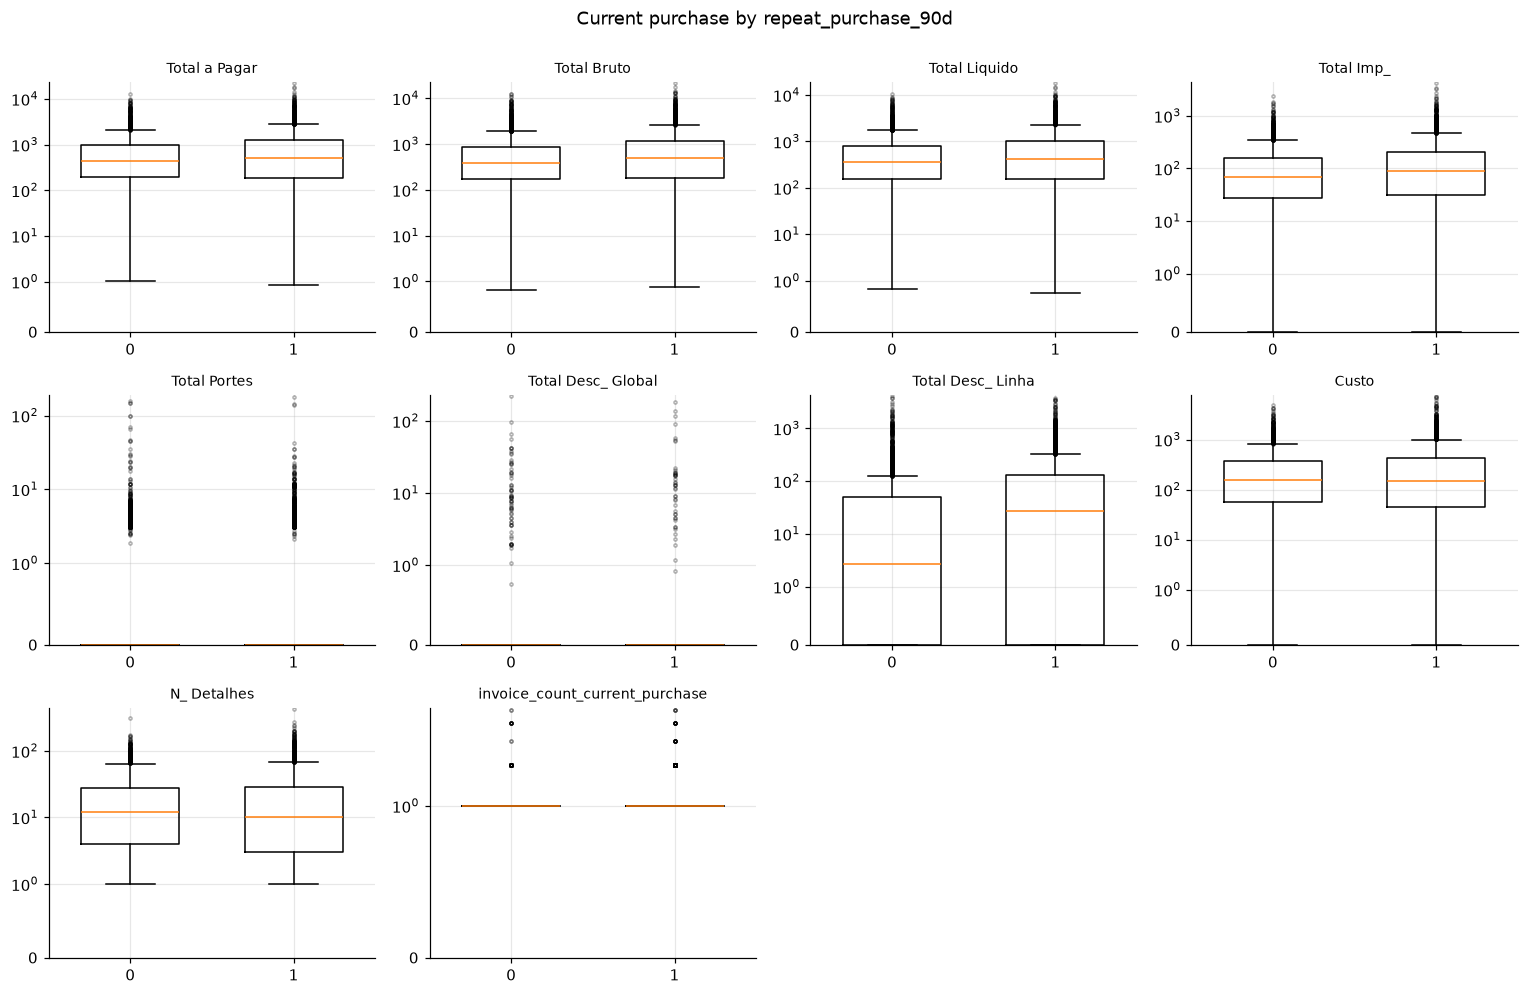

In [37]:
def boxplots_by_class(columns: list, title: str) -> None:
    # One box plot per column, class 0 next to class 1. Symlog y axis: the columns are skewed and many are 0.
    n_cols = 4
    n_rows = -(-len(columns) // n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 3 * n_rows), squeeze=False)
    for ax, col in zip(axes.flat, columns):
        ax.boxplot([class_0[col].dropna(), class_1[col].dropna()], widths=0.6,
                   flierprops={"markersize": 2, "alpha": 0.3})
        ax.set_xticks([1, 2], ["0", "1"])
        if col != "random_noise":
            ax.set_yscale("symlog", linthresh=1)
            ax.set_ylim(bottom=0)
        ax.set_title(col, fontsize=9)
    for ax in list(axes.flat)[len(columns):]:
        ax.set_visible(False)
    fig.suptitle(f"{title} by {CLS}", y=1.0)
    fig.tight_layout()
    plt.show()


boxplots_by_class(numeric[:10], "Current purchase")

The amounts overlap almost completely between the classes. Line discounts are clearly higher for class 1.
`Total Portes`, `Total Desc_ Global` and `invoice_count_current_purchase` are the same value (0, or 1 invoice) for
nearly every row, so they carry little information.

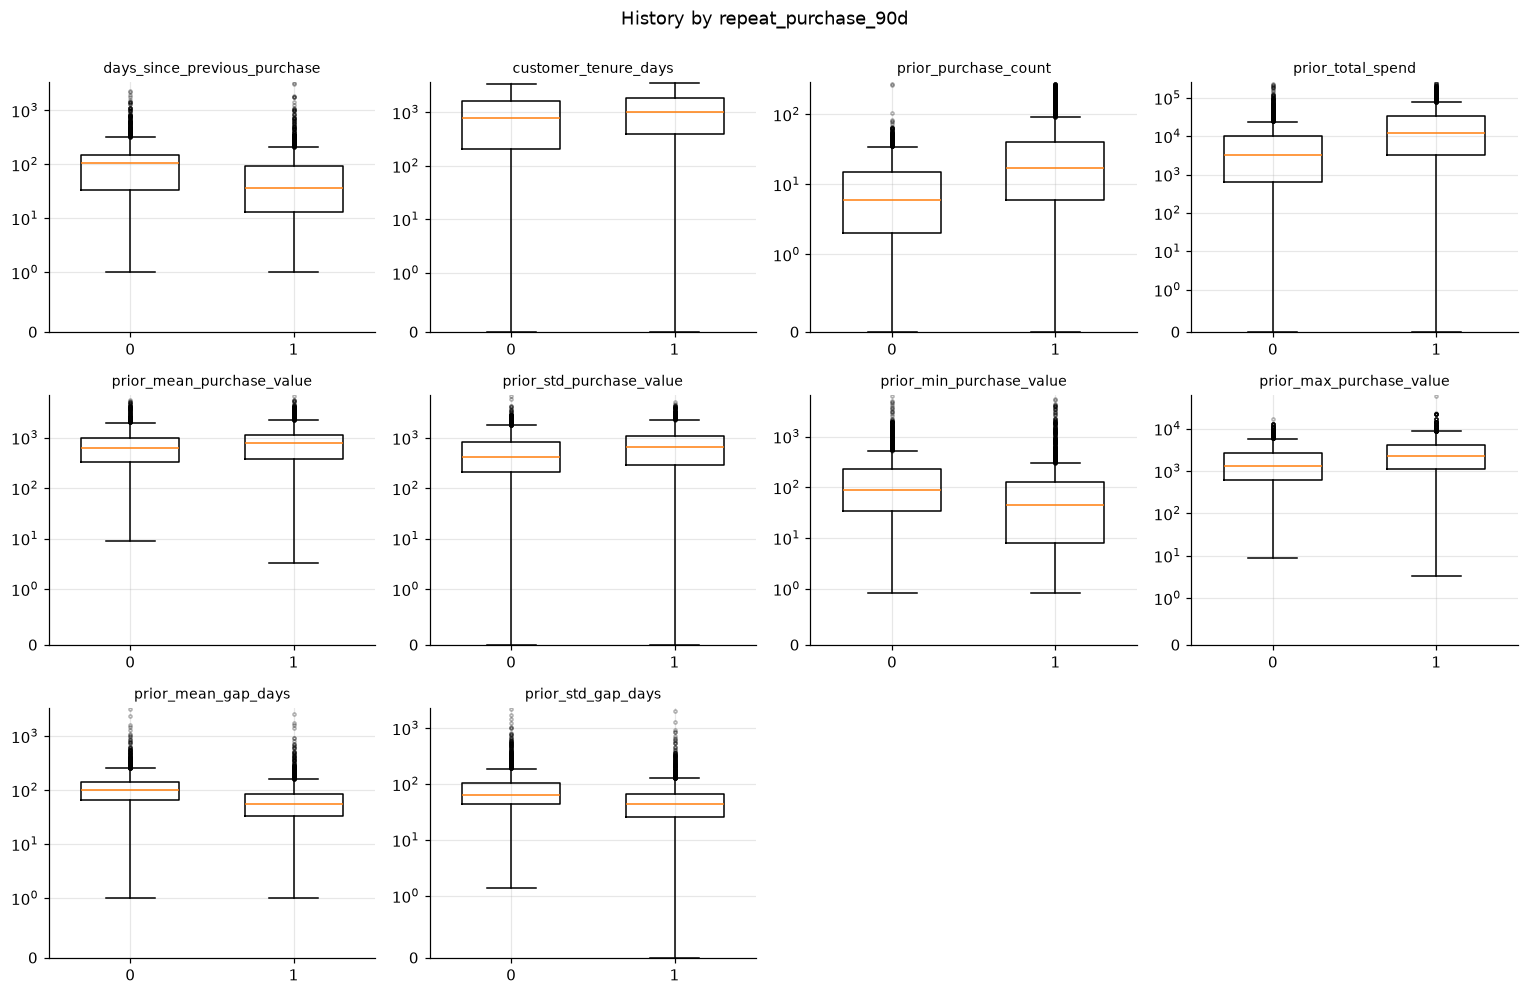

In [38]:
boxplots_by_class(numeric[10:20], "History")

Every history column shifts between the classes. Customers who return have more prior purchases, higher spend,
longer tenure, shorter gaps and a more recent last purchase. Their smallest purchase is *lower*, which fits having
more purchases (more chances of a small one). Count, spend and tenure probably carry overlapping information,
which the correlation/VIF section will check.

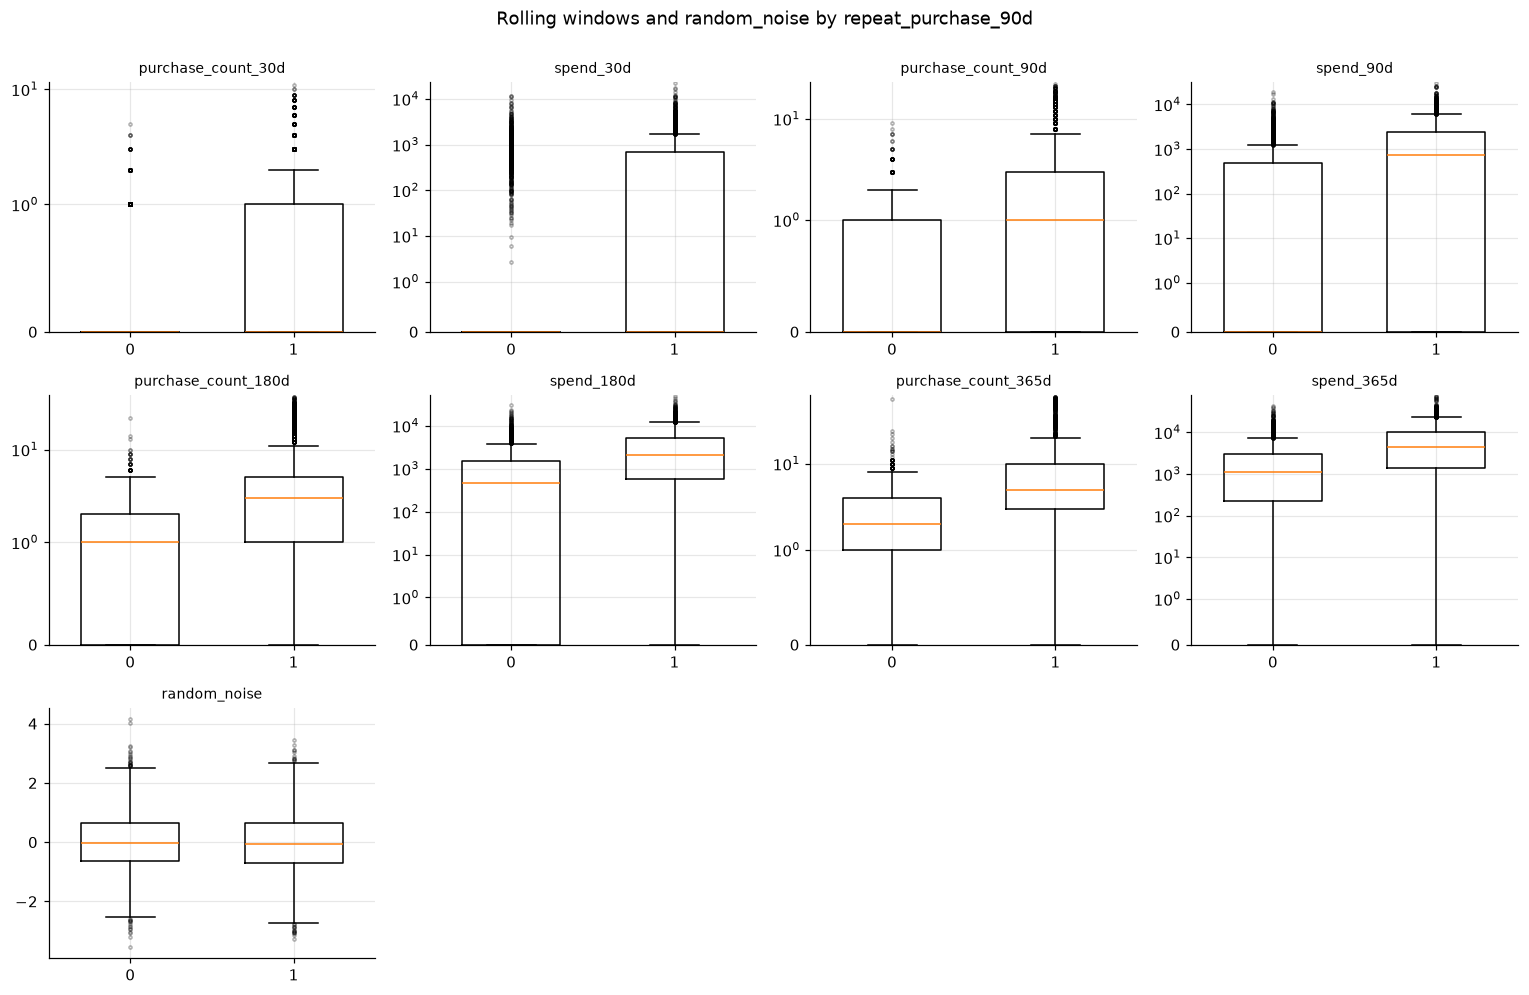

In [39]:
boxplots_by_class(numeric[20:], "Rolling windows and random_noise")

Recent activity is the clearest signal in the data. For class 0 the median 30- and 90-day counts are 0. For class 1
the median 90-day count is 1, and the 180- and 365-day windows are well above class 0. The two `random_noise` boxes
are identical.

### 7.3 Categorical features: positive rate by level

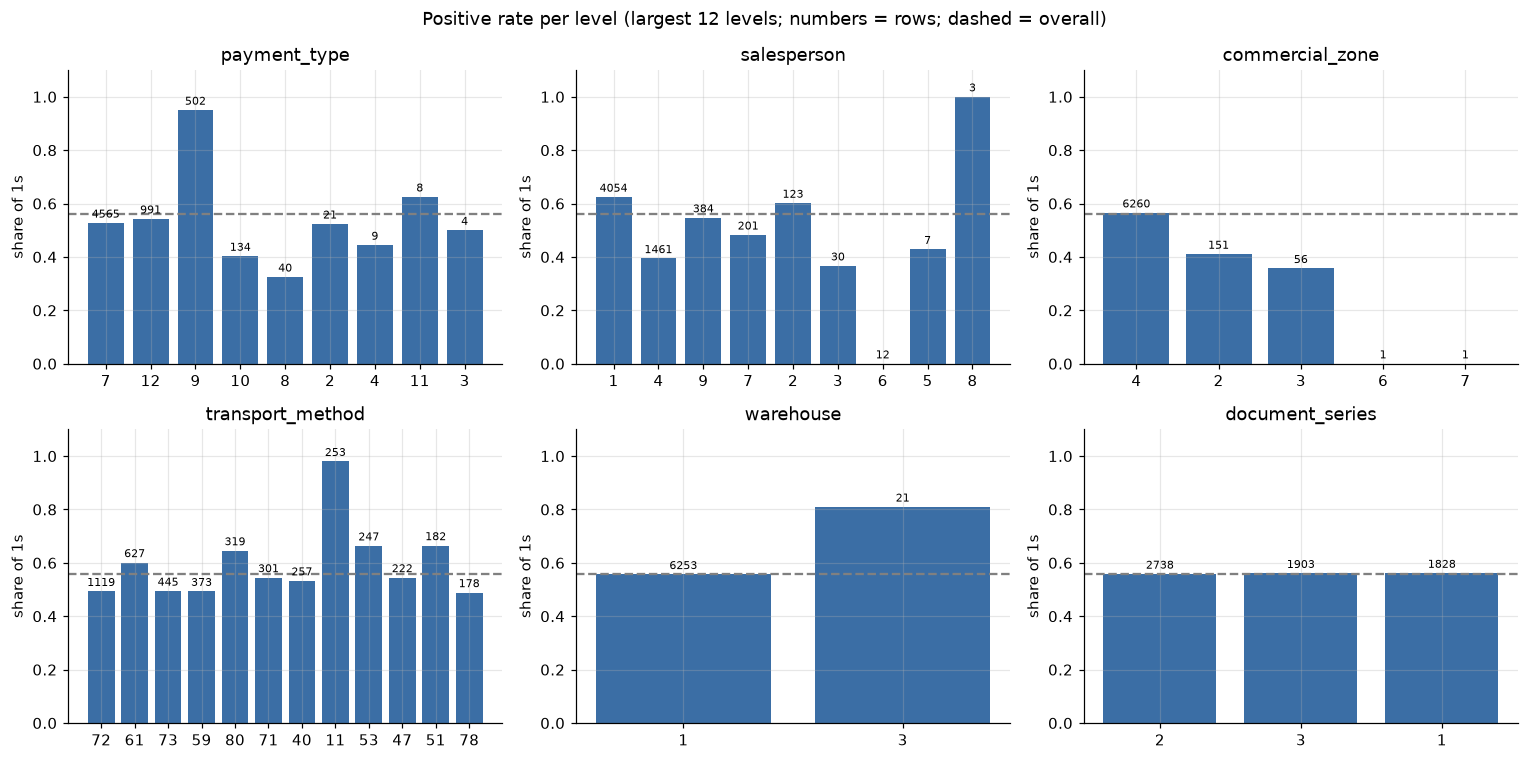

In [40]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, categorical):
    stats = view.groupby(col)[CLS].agg(rows="size", rate="mean").sort_values("rows", ascending=False).head(12)
    labels = stats.index.str.extract(r"(\d+)$")[0]     # the level number is enough on the axis
    ax.bar(labels, stats["rate"], color=COLOR)
    ax.axhline(view[CLS].mean(), color="grey", linestyle="--")
    for x, (n, r) in enumerate(zip(stats["rows"], stats["rate"])):
        ax.text(x, r + 0.02, n, ha="center", fontsize=7)
    ax.set(title=col, ylim=(0, 1.1), ylabel="share of 1s")
fig.suptitle("Positive rate per level (largest 12 levels; numbers = rows; dashed = overall)")
fig.tight_layout()
plt.show()

Some levels have a very different rate, like payment 9 (95%) and transport 11 (98%). Before reading them as signal:
customers repeat, so a level can be one big customer. The cell below lists the levels at least 15 points away from the
overall rate (20 rows or more), with the number of customers behind them.

In [41]:
overall = view[CLS].mean()
rows = []
for col in categorical:
    for level, group in view.groupby(col):
        if len(group) >= 20 and abs(group[CLS].mean() - overall) >= 0.15:
            per_customer = group[GROUP].value_counts()
            rows.append({"column": col, "level": level, "rows": len(group), "customers": len(per_customer),
                         "largest customer's share of rows": round(per_customer.iloc[0] / len(group), 2),
                         "positive rate": round(group[CLS].mean(), 3)})
pd.DataFrame(rows)

,column,level,rows,customers,largest customer's share of rows,positive rate
0,payment_type,Maybe Tomorrow Payment 10,134,23,0.14,0.403
1,payment_type,Maybe Tomorrow Payment 8,40,6,0.40,0.325
2,payment_type,Maybe Tomorrow Payment 9,502,10,0.42,0.950
3,salesperson,VLOOKUP Master 3,30,20,0.13,0.367
4,salesperson,VLOOKUP Master 4,1461,199,0.03,0.394
5,commercial_zone,Decorative Dashboard Zone 3,56,21,0.20,0.357
6,transport_method,Maybe Tomorrow Delivery 11,253,2,0.95,0.980
7,transport_method,Maybe Tomorrow Delivery 18,21,15,0.14,0.810
8,transport_method,Maybe Tomorrow Delivery 22,50,6,0.86,0.860
9,transport_method,Maybe Tomorrow Delivery 33,36,2,0.97,0.972


- **Payment 9** (95% return) comes from 10 customers, and its largest customer alone has 42% of the rows.
- **`transport_method` behaves like a customer identifier.** 13 of its levels are far from the overall rate, and
  for five of them (11, 22, 33, 42, 62) one customer has 76-100% of the rows. Transport 11 (98% return) is
  essentially one customer.
- These levels describe *who* the customer is, not a buying habit. A model can memorise them, and only a CV grouped
  by customer shows whether that generalises. This confirms the design choice of `StratifiedGroupKFold`.
- **Salesperson 4** is lower (39%) across 199 customers. That is a real spread, not one customer.
- **`commercial_zone`** is 97% zone 4, and zones 6 and 7 have one row each. Test has zones 1 and 5, never seen in
  train, covering 21% of test (customers-and-time section).
- **`document_series`** has the same rate in all three series, and test is entirely series 2. It carries no
  information, so it is a candidate to drop.

### Summary

- **Columns:** every column has one role (section 1). No spelling variants or text placeholders in the categoricals (3.2).
- **Targets:** `repeat_purchase_90d` is about 56/44 and stable over the years. `spend_next_90d` exists only for
  returning customers, 229 of them without a value, and has a long right tail.
- **Invalid values, in both files** (section 4): a 1e9 placeholder, a -4 code, sign-flipped negatives, and inflated
  values caught only by cross-column rules. Five columns are affected, 223 train rows and 31 test rows.
  `blank_invalid_values` turns them all into NaN and keeps every row.
- **Duplicates:** none, by row or by customer + date (section 5).
- **Missing values** (section 6):
  - Structural gaps in the history columns, explained by the number of prior purchases: handle by rule, not by
    a median.
  - About 3% independent gaps in eight columns, all MCAR: a simple fill, no flags.
  - 65 empty rows: drop from training.
- **Signal** (section 7): customer history and recent activity separate the classes, while the current purchase
  barely does. Some categorical levels (payment 9, many transport methods) are essentially single customers, so
  grouped CV matters. `document_series`,
  `Total Portes`, `Total Desc_ Global` and `random_noise` look uninformative.

**Candidate rows for the verdict table so far:**

| Issue | Where | Action |
|---|---|---|
| 1e9 placeholder | `prior_mean_purchase_value`, `spend_365d` | NaN in `cleaning.py` |
| -4 code / negatives | `days_since_previous_purchase`, `prior_mean_gap_days`, `prior_mean_purchase_value`, `spend_365d` | NaN in `cleaning.py` |
| inflated values (cross-column rules) | `prior_mean_purchase_value`, `prior_max_purchase_value`, `spend_365d` | NaN in `cleaning.py` |
| structural history gaps | `prior_*`, `days_since_previous_purchase` | rule-based fill (to decide in preprocessing) |
| MCAR gaps, about 3% | 8 columns (6.2) | median / most frequent in the Pipeline, no flags |
| empty rows | 65 train rows | drop from training only |
| redundant by construction | `Total Liquido`, `Total a Pagar`, `prior_mean_purchase_value` | confirm with VIF |
| no signal | `document_series`, `random_noise` | candidates to drop (`random_noise` stays as a sanity check) |